In [1]:
# Änderungen:
# Vorläufiges Splitten nach Hotel bei Modellen (nur Entscheidungsbaum), vielleicht zu viel und unnötig
# Handhabung Vorhersage falls Splitten am Besten

# Weitere Features in features() aufgenommen

# Weitere Änderungen
# Land und agentur durch stoniert in Risikogruppen einteilen und map erstellen (dictonary) + Verteilungsplot erstellt
# zimmer umgebucht
# marktsegment == buchungskanal
# Kontinentmapping entfernt

# Gurobi verstehen, dokumentieren


# TODO:
# Mehr Datenanalyse, Plots usw. (zB Entwicklung vorlaufzeit / stornierungsrate)

# Modelle Hyperparamater anpassen

#       Hotels getrennt
#       Vorlaufzeit = 0 als Feature (vor Ort) als extra Spalte
#       Frühere Buchung / Stornierung in Prozent

# Erwachsene / Kinder / Babys OHE
#       Anmerkung: Da wir überwiegend Bäume (und diese auch am Besten sein werden) verwenden, macht das dann noch Sinn, schließlich würden
#           Splits wie Kinder < 3 nicht mehr funktionieren?
#       Und dass es keinen linearen Zusammenhang gibt, müssten Bäume ja auch von selbst lernen können?
#       Würde diese numerisch lassen

### Überlegungen:

Feature: Erwachsene / Kinde / Babys - Hier hatten wir es für sinnvoll gehalten, diese mit OHE zu transformieren. Da Bäume jedoch die besten Resultate erzielen, und diese das Fehlen eines linearen Zusammenhangs selbst lernen, haben wir diese Idee gestrichen.  

# (1) Betrachtung der Daten

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

CV = 5  # GridSearchCV: Anzahl Kreuzvalidierungen
VERBOSE = 1  # GridSearchCV: Informationsgehalt der Ausgaben
N_JOBS = -1  # Anzahl an Parallel laufbaren Jobs (-1 = Nutze alle verfügbaren Kerne)

df_train = pd.read_csv("data/buchungen.csv")
df_test = pd.read_csv("data/buchungen_test.csv")  # Test-Datensatz ohne Storniert-Status

display(df_train.dtypes)  # Ausgabe der Spalten und deren jeweiligen Datentyp
display(df_train)

hotel_typ                          str
storniert                        int64
anreisedatum                       str
vorlaufzeit_tage                 int64
naechte_wochenende               int64
naechte_wochentag                int64
erwachsene                       int64
kinder                         float64
babys                            int64
verpflegung                        str
herkunftsland                      str
marktsegment                       str
buchungskanal                      str
stammgast                        int64
frueh_stornierungen              int64
frueh_buchungen_eingehalten      int64
gebuchter_zimmertyp                str
zugewiesener_zimmertyp             str
buchungsaenderungen              int64
anzahlungsart                      str
agentur_id                     float64
warteliste_tage                  int64
kundentyp                          str
durchschn_tagespreis           float64
parkplaetze_benoetigt            int64
anzahl_sonderwuensche    

,hotel_typ,storniert,anreisedatum,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,verpflegung,...,buchungsaenderungen,anzahlungsart,agentur_id,warteliste_tage,kundentyp,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,reservierungsstatus,reservierungsstatus_datum
0,Ferienhotel,0,2015-07-01,340,0,0,2,0.0,0,Frühstück,...,3,Ohne Anzahlung,NaN,0,Einzelbucher,0.61,0,0,Ausgecheckt,2015-07-01
1,Ferienhotel,0,2015-07-01,738,0,0,2,0.0,0,Frühstück,...,4,Ohne Anzahlung,NaN,0,Einzelbucher,0.97,0,0,Ausgecheckt,2015-07-01
2,Ferienhotel,0,2015-07-01,14,0,1,1,0.0,0,Frühstück,...,0,Ohne Anzahlung,304.0,0,Einzelbucher,75.98,0,0,Ausgecheckt,2015-07-02
3,Ferienhotel,0,2015-07-01,14,0,2,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,240.0,0,Einzelbucher,98.18,0,1,Ausgecheckt,2015-07-03
4,Ferienhotel,0,2015-07-01,0,0,2,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,NaN,0,Einzelbucher,106.52,0,0,Ausgecheckt,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95507,Stadthotel,0,2017-08-30,22,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,394.0,0,Einzelbucher,95.82,0,2,Ausgecheckt,2017-09-06
95508,Stadthotel,0,2017-08-30,21,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,394.0,0,Einzelbucher,96.24,0,0,Ausgecheckt,2017-09-06
95509,Stadthotel,0,2017-08-31,32,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,9.0,0,Einzelbucher,157.43,0,4,Ausgecheckt,2017-09-07
95510,Stadthotel,0,2017-08-31,110,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,89.0,0,Einzelbucher,104.14,0,0,Ausgecheckt,2017-09-07


## Auffälligkeiten

Stadhotel hat eine deutlich höhere Stornierungsrate im Vergleich zu Ferienhotel - möglicherweise werden Urlaube grundsätzlich besser geplant.  
Buchungen vor Ort und kurzfristige Buchungen haben eine verhältnismäßig geringe Stornierungsrate, was zu erwarten ist, da weniger Zeit für eine Stornierung verbleibt.  
  
Es gibt bei den meisten numerischen Kategorien starke Ausreißer, die wir in der Pipeline später dann entfernen.
  
Die Korrelationen haben wir weiter unter betrachtet.

Stornierungsraten:
Gesamt:                  37.04 %
Ferienhotel:             28.05 %
Stadthotel:              41.56 %
Buchungen vor Ort:       7.75 %
Kurzfristige Buchungen:  18.52 %


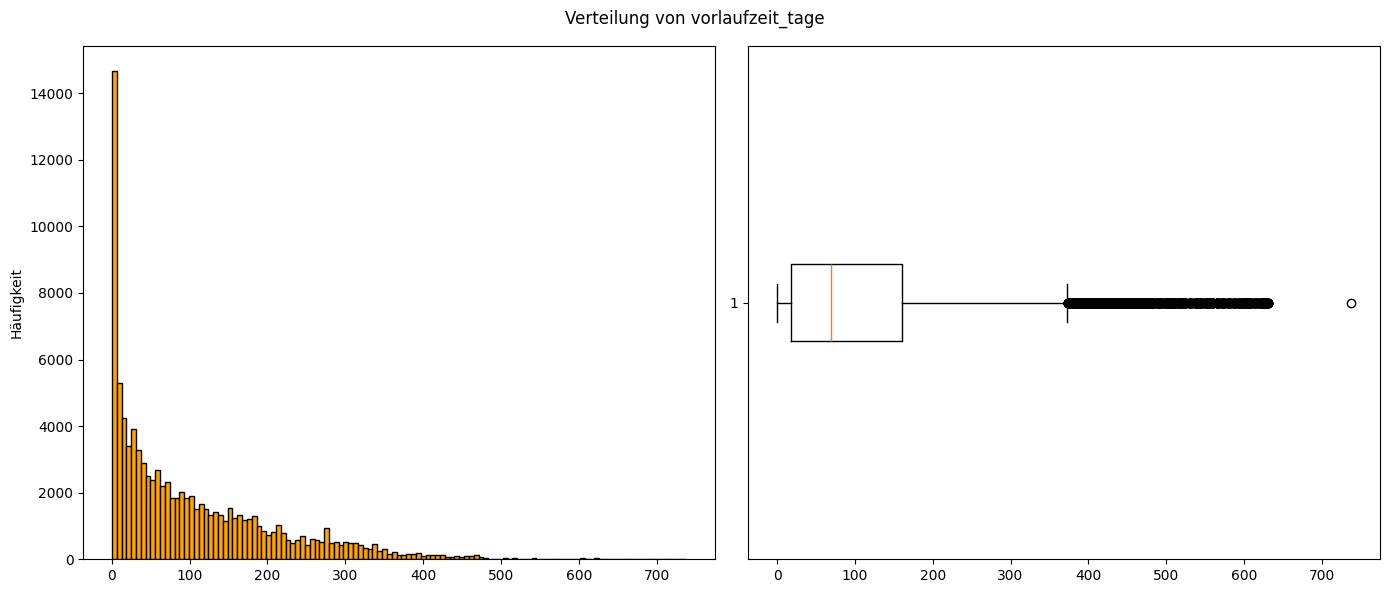

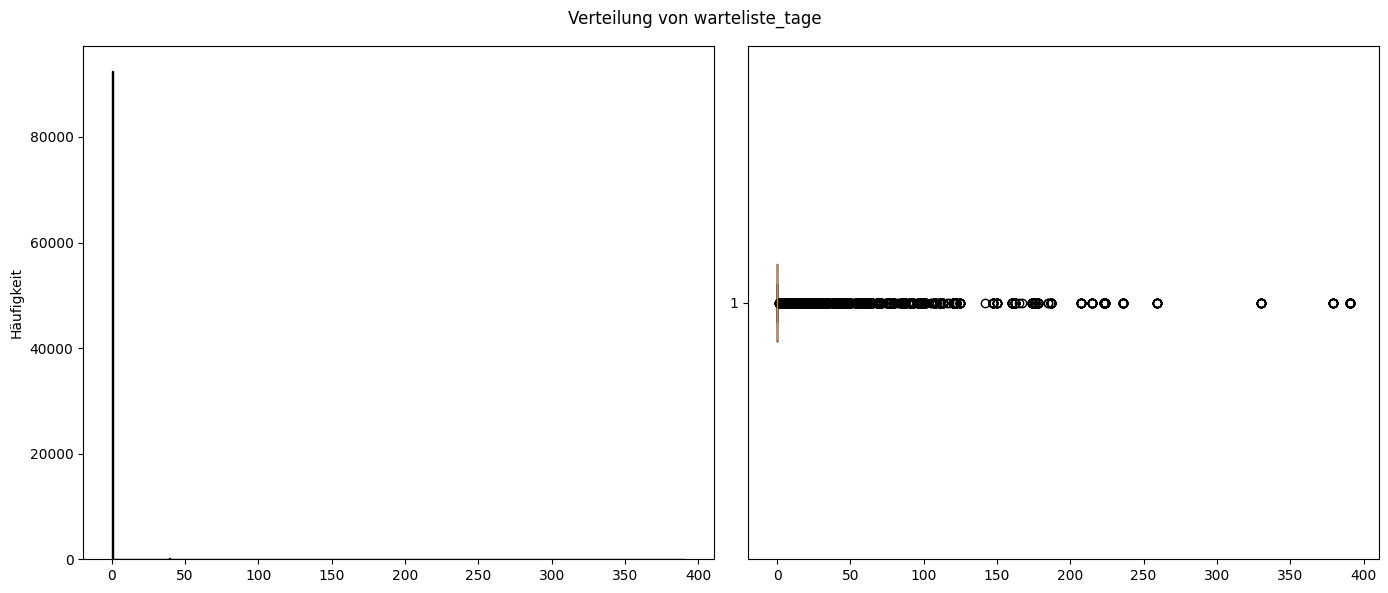

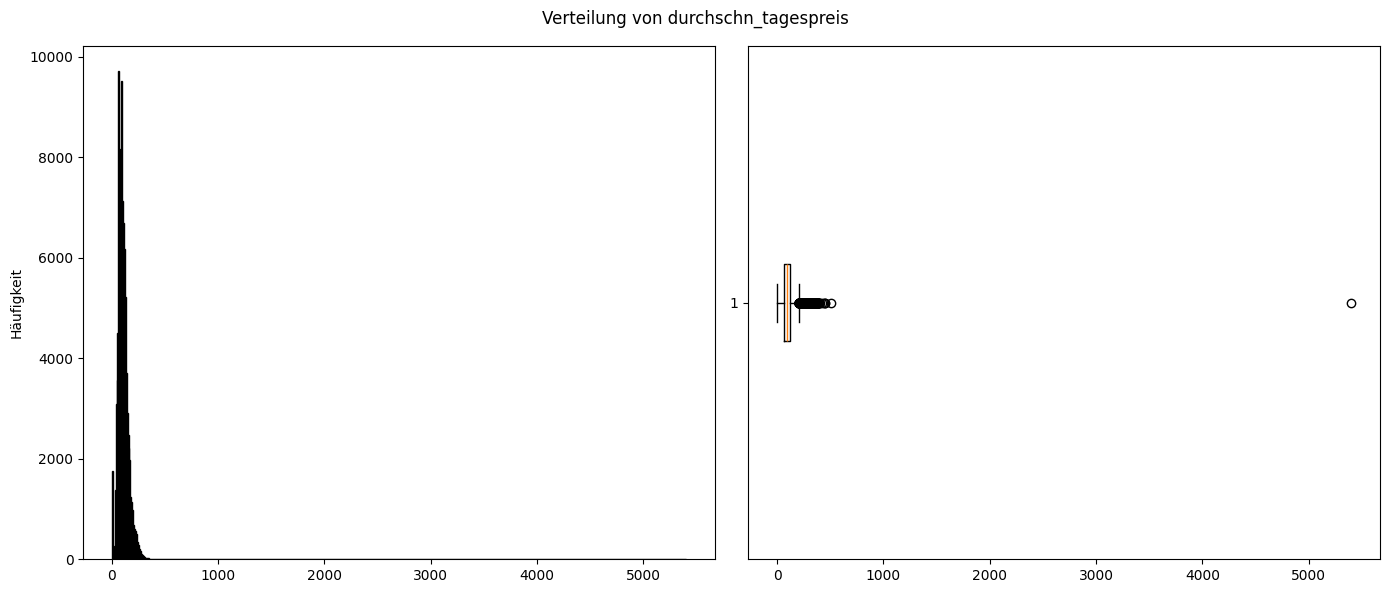

In [3]:
df = df_train.copy()

# Allgemeine Stornierungsrate
cancel_rate = float(df.loc[df["storniert"] == 1]["storniert"].count() / df["storniert"].count() * 100)

# Stornierungsraten nach Hotels
df_type = df[df["hotel_typ"] == "Ferienhotel"]
cancel_rate_holiday = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

df_type = df[df["hotel_typ"] == "Stadthotel"]
cancel_rate_city = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

# Buchungen vor Ort und kurzfristige
df_type = df[df["vorlaufzeit_tage"] == 0]
cancel_rate_vorlaufzeit = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

df_type = df[df["vorlaufzeit_tage"] < 31]
cancel_rate_recent_resv = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

print(
    f"Stornierungsraten:\n"
    f"Gesamt:                  {cancel_rate:.2f} %\n"
    f"Ferienhotel:             {cancel_rate_holiday:.2f} %\n"
    f"Stadthotel:              {cancel_rate_city:.2f} %\n"
    f"Buchungen vor Ort:       {cancel_rate_vorlaufzeit:.2f} %\n"
    f"Kurzfristige Buchungen:  {cancel_rate_recent_resv:.2f} %"
)

# Wir haben grundsätzlich alle numerischen Kategorien betrachtet, hier eine Auswahl:
for column in ["vorlaufzeit_tage", "warteliste_tage", "durchschn_tagespreis"]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].hist(df[column].dropna(), bins="auto", color="orange", edgecolor="black")
    axes[0].set_ylabel("Häufigkeit")

    axes[1].boxplot(df[column].dropna(), vert=False)

    plt.suptitle(f"Verteilung von {column}")
    plt.tight_layout()
    plt.show()

Hier betrachten wir die Stornierungsraten von verschiedenen Vorlaufszeiten.

Dabei fällt auf, dass kurzfristige Vorlaufszeiten (1 Monat) eine deutlich geringere Stornierungsrate haben. 

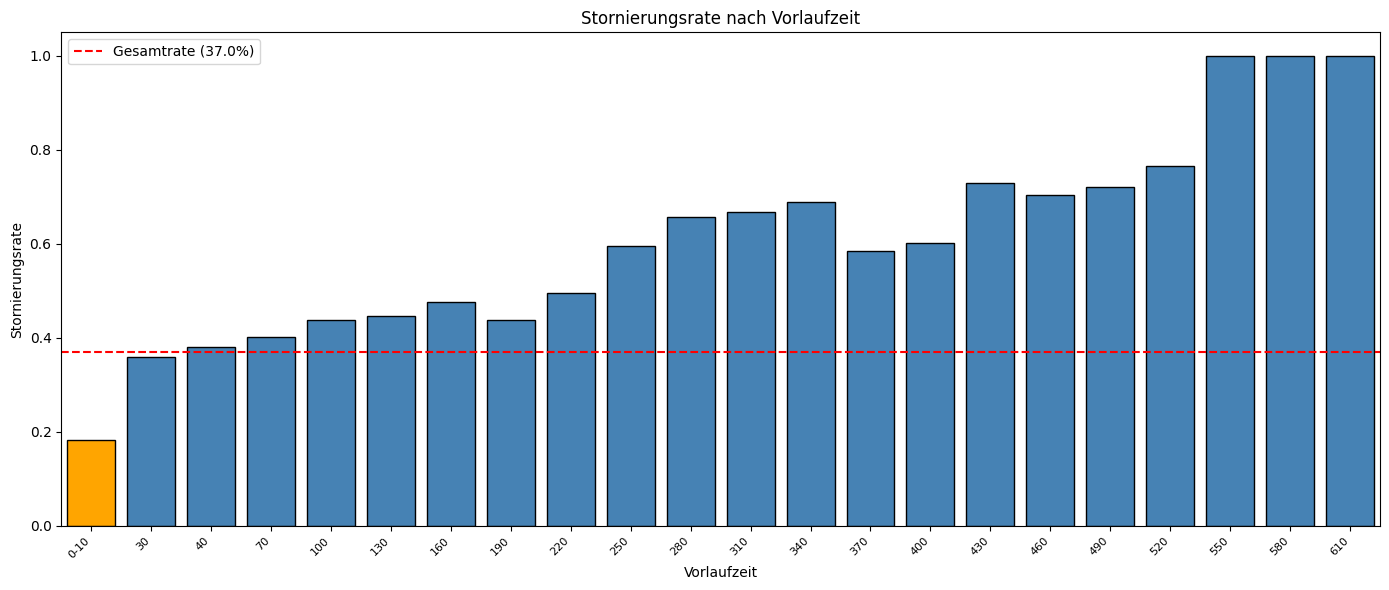

In [4]:
fig, ax = plt.subplots(figsize=(14, 6))

# Erster Bin: [0, 10), danach 30-Tage-Bins ab 10
max_vorlauf = int(df["vorlaufzeit_tage"].max())
alle_bins = [0, 30] + list(range(40, max_vorlauf + 30, 30))

gruppe_stats = (
    df[["vorlaufzeit_tage", "storniert"]]
    .assign(gruppe=pd.cut(df["vorlaufzeit_tage"], bins=alle_bins, right=False))
    .groupby("gruppe", observed=True)["storniert"]
    .agg(["mean", "count"])
)
storno_rate = gruppe_stats[gruppe_stats["count"] >= 30]["mean"]

farben = ["orange"] + ["steelblue"] * (len(storno_rate) - 1)

ax.bar(range(len(storno_rate)), storno_rate.values, color=farben, edgecolor="black")
ax.axhline(df["storniert"].mean(), color="red", linestyle="--", linewidth=1.5, label=f"Gesamtrate ({df['storniert'].mean():.1%})")

ax.set_xticks(range(len(storno_rate)))
ax.set_xticklabels(
    ["0-10"] + [str(int(b.left)) for b in storno_rate.index[1:]],
    rotation=45,
    ha="right",
    fontsize=8,
)
ax.set_xlim(-0.5, len(storno_rate) - 0.5)
ax.set_ylabel("Stornierungsrate")
ax.set_xlabel("Vorlaufzeit")
ax.legend()

plt.title("Stornierungsrate nach Vorlaufzeit")
plt.tight_layout()
plt.show()

# (2 / 3) Vorverarbeitung und Feature Engineering

In [5]:
# Anzahl Feiertage im Buchungszeitraum
# Anzahl der Feiertage ist aussagekräftiger als welcher spezifische Feiertag 
df_holidays = pd.read_csv("data/portugal_feiertage.csv")
df_holidays["datum"] = pd.to_datetime(df_holidays["datum"])
df_holidays = df_holidays.set_index("datum")


def map_holidays(df: pd.DataFrame) -> pd.DataFrame:
    """Berechnet die Anzahl an Feiertage innerhalb eines Buchungszeitraumes als neues Feature."""
    df = df.copy()
    df["abreisedatum"] = df["anreisedatum"] + pd.to_timedelta((df["naechte_wochenende"] + df["naechte_wochentag"]), unit="D")

    df["anzahl_feiertage"] = 0
    for d in df_holidays.index:
        df["anzahl_feiertage"] += ((df["anreisedatum"] <= d) & (df["abreisedatum"] >= d)).astype(int)

    return df.drop(columns=["abreisedatum"])

In [6]:
# Risikogruppen haben sich als deutlich stärkeres Feature als die spezifischen Agenturen und Herkunftsländer herausgestellt

N_GRUPPEN = 5
MIN_BUCHUNGEN = 20
RISIKO_GRENZEN = [0.0, 0.20, 0.35, 0.50, 0.70, 1.0]


def get_cancel_rates(df: pd.DataFrame, column: str, min_buchungen: int = MIN_BUCHUNGEN) -> pd.DataFrame:
    df = df.copy()
    rates = df.groupby(column)["storniert"].agg(["mean", "count"]).rename(columns={"mean": "stornierungsrate", "count": "anzahl"})
    return rates[rates["anzahl"] >= min_buchungen]


def assign_risk_groups(rates: pd.DataFrame, n_gruppen: int = N_GRUPPEN) -> pd.Series:
    return pd.cut(
        rates["stornierungsrate"],
        bins=RISIKO_GRENZEN,
        labels=list(range(n_gruppen)),
        include_lowest=True,
    ).astype(int)

In [7]:
import matplotlib.patches as mpatches

RISIKO_FARBEN = ["green", "yellow", "orange", "red", "purple"]
RISIKO_LABELS = ["Niedrig", "Mittel-niedrig", "Mittel-hoch", "Hoch", "Sehr-hoch"]


def plot_cancel_rate_risk_groups(df: pd.DataFrame) -> None:
    land_rates = get_cancel_rates(df, "herkunftsland")
    agentur_rates = get_cancel_rates(df, "agentur_id")

    land_rates["risikogruppe"] = assign_risk_groups(land_rates)
    agentur_rates["risikogruppe"] = assign_risk_groups(agentur_rates)

    # Legende mit Prozentbereichen
    legend_patches = [
        mpatches.Patch(
            facecolor=RISIKO_FARBEN[i],
            edgecolor="gray",
            linewidth=0.5,
            label=f"Gruppe {i} - {RISIKO_LABELS[i]}  ({RISIKO_GRENZEN[i]:.0%}-{min(RISIKO_GRENZEN[i + 1], 1.0):.0%})",
        )
        for i in range(N_GRUPPEN)
    ]

    for rates, titel_base in [
        (land_rates, "Herkunftsland"),
        (agentur_rates, "Agentur-ID"),
    ]:
        n = len(rates)
        fig, (ax_hist, ax_bars) = plt.subplots(
            1,
            2,
            figsize=(18, 10),
        )
        fig.suptitle(f"Stornierungsraten - {titel_base}", fontsize=13)

        # 1. Plot: Häufigkeitsverteilung der Stonierungsraten
        _, bin_edges, patches = ax_hist.hist(
            rates["stornierungsrate"],
            bins=20,
            edgecolor="black",
            linewidth=0.4,
        )
        bin_width = bin_edges[1] - bin_edges[0]

        # Bins nach Risikogruppe einfärben
        for patch, left in zip(patches, bin_edges[:-1]):
            midpoint = left + bin_width / 2
            gruppe = pd.cut(
                [midpoint],
                bins=RISIKO_GRENZEN,
                labels=list(range(N_GRUPPEN)),
                include_lowest=True,
            )[0]
            patch.set_facecolor(RISIKO_FARBEN[int(gruppe)] if pd.notna(gruppe) else "lightgray")

        # Linie für Mittelwert und Median
        stat_handles = [
            plt.Line2D([0], [0], color="red", linestyle="--", linewidth=1.5, label=f"Mittelwert ({rates['stornierungsrate'].mean():.1%})"),
            plt.Line2D([0], [0], color="black", linestyle=":", linewidth=1.5, label=f"Median ({rates['stornierungsrate'].median():.1%})"),
        ]
        ax_hist.axvline(rates["stornierungsrate"].mean(), color="red", linestyle="--", linewidth=1.5)
        ax_hist.axvline(rates["stornierungsrate"].median(), color="black", linestyle=":", linewidth=1.5)

        ax_hist.set_xlabel("Stornierungsrate")
        ax_hist.set_xlim(0, 1)
        ax_hist.set_ylabel("Anzahl Gruppen")
        ax_hist.set_title(f"Häufigkeitsverteilung  (n={n}, >={MIN_BUCHUNGEN} Buchungen)")
        ax_hist.legend(handles=legend_patches + stat_handles, fontsize=7.5, loc="upper right")

        # 2. Plot: Gruppen sortiert nach Stornierungsrate
        sorted_rates = rates.sort_values("stornierungsrate", ascending=True)
        bar_colors = [RISIKO_FARBEN[g] for g in sorted_rates["risikogruppe"]]

        ax_bars.barh(
            sorted_rates.index.astype(str),
            sorted_rates["stornierungsrate"],
            color=bar_colors,
            edgecolor="black",
            linewidth=0.5,
            height=1,  # Balkenbreite
        )

        # Whitespace oben/unten entfernen
        ax_bars.set_ylim(-0.5, n - 0.5)

        ax_bars.set_xlabel("Stornierungsrate")
        ax_bars.set_xlim(0, 1)
        ax_bars.set_title(f"Alle {n} Gruppen - sortiert nach Stornierungsrate")
        ax_bars.tick_params(axis="y", labelsize=max(5, min(8, 350 / n)))
        ax_bars.legend(handles=legend_patches, fontsize=7.5, loc="upper right")

        plt.tight_layout()
        plt.show()

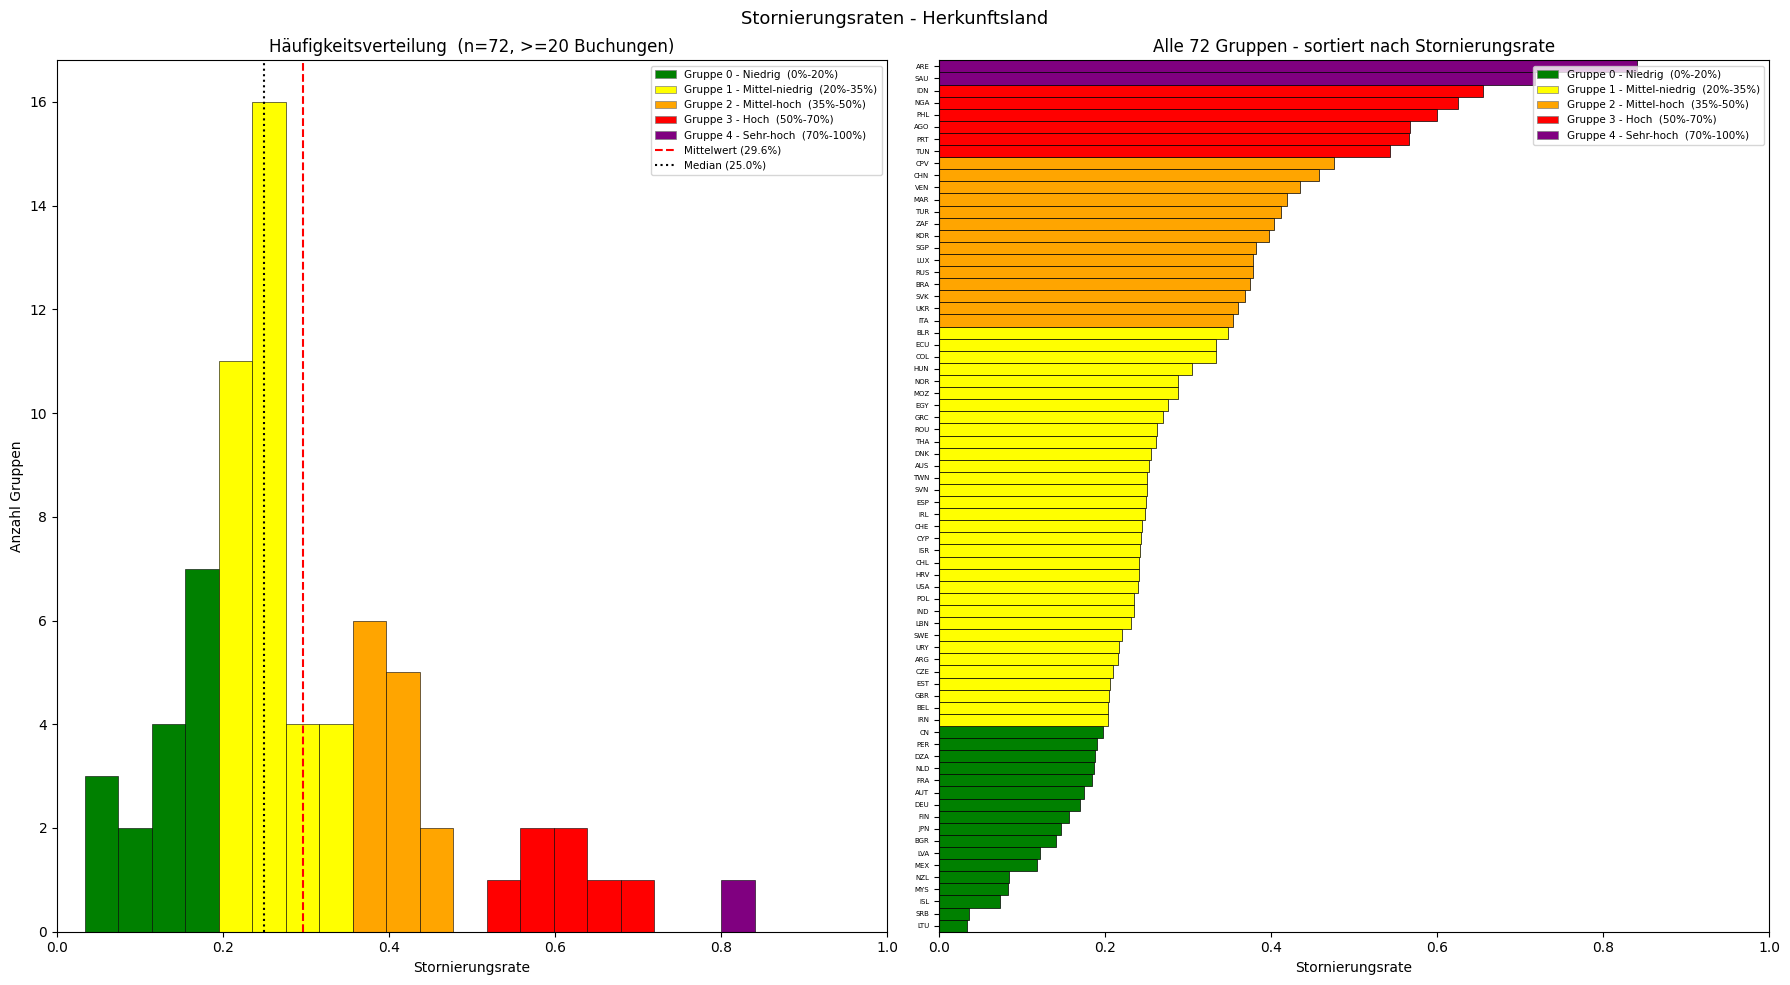

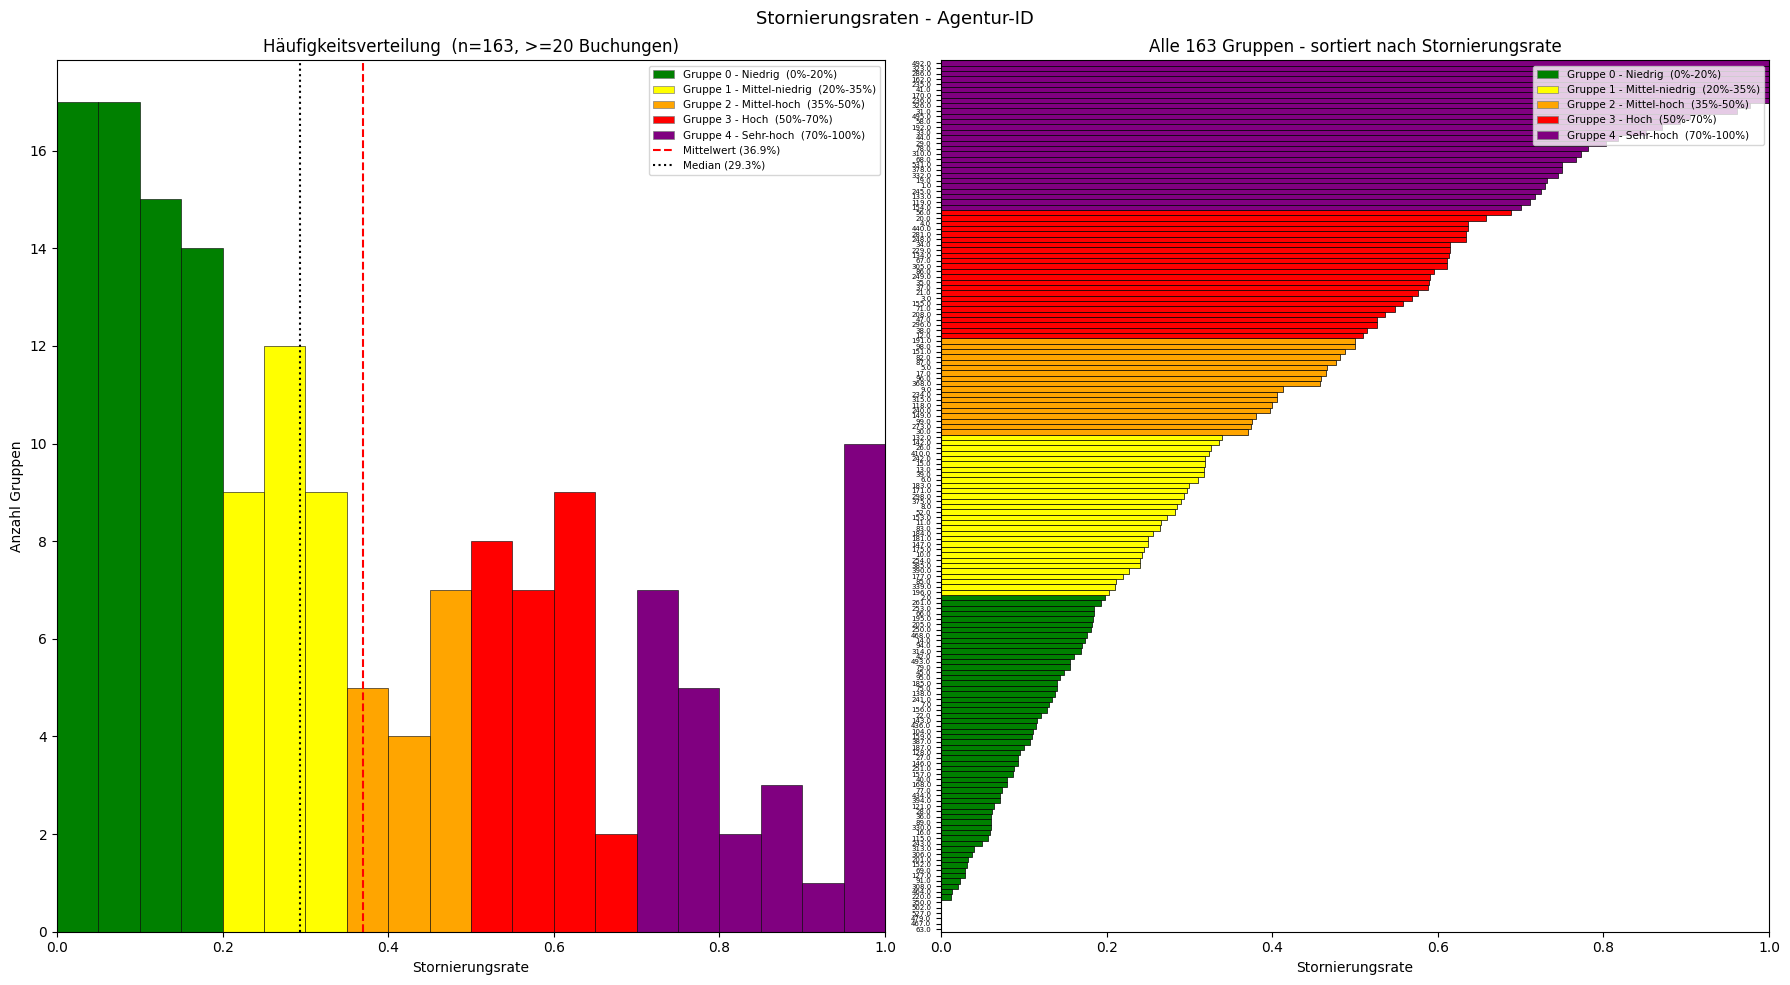

In [8]:
plot_cancel_rate_risk_groups(df_train)

In [9]:
UNBEKANNTE_RISIKOGRUPPE = 0  # Niedrigstes Risiko

def features(df: pd.DataFrame, drop: list | None = None, mapping: list = []) -> pd.DataFrame:
    """Generiert oder transformiert neue Features."""
    drop = [] if drop is None else drop
    df = df.copy()

    df["anreisedatum"] = pd.to_datetime(df["anreisedatum"])
    df["stammgast"] = df["stammgast"].astype(str)  # Stammgast ist kategorisch
    df["agentur_id"] = df["agentur_id"].astype("Int64")  # Agenturen sind als float gespeichert

    df["herkunftsland_risiko"] = df["herkunftsland"].map(mapping[0]).fillna(UNBEKANNTE_RISIKOGRUPPE).astype(int)
    df["agentur_risiko"] = df["agentur_id"].map(mapping[1]).fillna(UNBEKANNTE_RISIKOGRUPPE).astype(int)

    # Buchungen direkt vor Ort haben eine geringe Stornierungsrate
    df["buchung_vor_ort"] = (df["vorlaufzeit_tage"] < 31).astype(int)

    # Zimmertypen haben keine Aussagekraft, aber ob der Typ geändert wurde schon 
    df["zimmer_geaendert"] = (df["gebuchter_zimmertyp"] != df["zugewiesener_zimmertyp"]).astype(int)

    # Additive Glättung (auch Laplace Glättung) verhindert unnütze extreme Raten (wie 1 Stornierung/1 Gesamt => 100%)
    alpha = 2
    merkmale = 2
    df["frueh_stornierungsrate"] = (df["frueh_stornierungen"] + alpha) / (df["frueh_stornierungen"] + df["frueh_buchungen_eingehalten"] + alpha * merkmale)

    df = map_holidays(df)

    return df.drop(
        columns=[
            *drop,
            "anreisedatum",
            "herkunftsland",
            "agentur_id",
            "gebuchter_zimmertyp",
            "zugewiesener_zimmertyp",
            "frueh_stornierungen",
            "frueh_buchungen_eingehalten",
            "buchungskanal",  # Buchungskanal zeigt hohe Korrelation zu Marksegment
        ]
    )

In [10]:
from sklearn.model_selection import train_test_split

# Duplizierte Datenpunkte entfernen (hier vor dem Split)
print(f"Anzahl Duplikate: {df_train.duplicated().sum()}")
df_train = df_train.drop_duplicates()
df_train["agentur_id"] = df_train["agentur_id"].astype("Int64")  # Agenturen sind als float gespeichert

# Im Folgendem wird nur noch der Trainingsdatensatz betrachtet um Data Leakage zu vermeiden
X_train, X_valid, y_train, y_valid = train_test_split(
    df_train.drop(columns=["storniert"]),
    df_train["storniert"],
    test_size=0.2,
    random_state=42,
)

_df_mapping = X_train.copy()
_df_mapping["storniert"] = y_train

herkunftsland_mapping = assign_risk_groups(get_cancel_rates(_df_mapping, "herkunftsland")).to_dict()
agentur_mapping = assign_risk_groups(get_cancel_rates(_df_mapping, "agentur_id")).to_dict()

X_train = features(X_train, ["reservierungsstatus", "reservierungsstatus_datum"], [herkunftsland_mapping, agentur_mapping])
X_valid = features(X_valid, ["reservierungsstatus", "reservierungsstatus_datum"], [herkunftsland_mapping, agentur_mapping])


categorical = X_train.select_dtypes(exclude=np.number).columns
numerical = X_train.select_dtypes(include=np.number).columns

Anzahl Duplikate: 286


In [11]:
# Ausgabe kategorischer Features
print(f"Kategorische Features ({len(categorical)}):\n")
for col in categorical:
    n_unique = X_train[col].nunique()
    print(f"{col:25} {n_unique:5} eindeutige Werte")

display("Trainingsdatensatz (kategorische Features):", X_train[categorical])

# Spalten die fehlende Werte enthalten ausgeben
missing = X_train.isna().sum()
display("Spalten mit fehlenden Werten:", missing[missing > 0])

# Ausreißern veranschaulichen
display(
    "Verteilung numerischer Features:",
    X_train.select_dtypes(include=np.number).describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999]),
)

Kategorische Features (6):

hotel_typ                     2 eindeutige Werte
verpflegung                   5 eindeutige Werte
marktsegment                  8 eindeutige Werte
stammgast                     2 eindeutige Werte
anzahlungsart                 3 eindeutige Werte
kundentyp                     4 eindeutige Werte


'Trainingsdatensatz (kategorische Features):'

,hotel_typ,verpflegung,marktsegment,stammgast,anzahlungsart,kundentyp
76374,Stadthotel,Frühstück,Online Reisebüro,0,Ohne Anzahlung,Einzelbucher
66460,Stadthotel,Frühstück,Direktbuchung,0,Ohne Anzahlung,Einzelbucher
82131,Stadthotel,Frühstück,Offline Reisebüro,0,Ohne Anzahlung,Einzelbucher
44586,Stadthotel,Frühstück,Online Reisebüro,0,Ohne Anzahlung,Einzelbucher
49014,Stadthotel,Frühstück,Direktbuchung,0,Ohne Anzahlung,Einzelbucher
...,...,...,...,...,...,...
6277,Ferienhotel,Frühstück,Online Reisebüro,0,Ohne Anzahlung,Einzelbucher
55072,Stadthotel,Frühstück,Online Reisebüro,0,Ohne Anzahlung,Einzelbucher
77084,Stadthotel,Frühstück,Offline Reisebüro,0,Ohne Anzahlung,Einzelbucher
860,Ferienhotel,Frühstück,Online Reisebüro,0,Ohne Anzahlung,Einzelbucher


'Spalten mit fehlenden Werten:'

kinder    3
dtype: int64

'Verteilung numerischer Features:'

,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,buchungsaenderungen,warteliste_tage,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,herkunftsland_risiko,agentur_risiko,buchung_vor_ort,zimmer_geaendert,frueh_stornierungsrate,anzahl_feiertage
count,76180.000000,76180.000000,76180.000000,76180.000000,76177.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000
mean,103.834602,0.929942,2.498307,1.858112,0.103260,0.007981,0.220924,2.293712,101.953647,0.062930,0.574587,1.692715,1.504804,0.324757,0.124390,0.499894,0.176424
std,106.767568,0.998556,1.911787,0.584068,0.397326,0.101392,0.655072,17.337603,51.788280,0.247444,0.794688,1.199322,1.267559,0.468287,0.330028,0.044111,0.411521
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.055556,0.000000
5%,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,38.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000
10%,3.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,50.609000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000
25%,18.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,69.310000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.500000,0.000000
50%,69.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,94.470000,0.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.500000,0.000000
75%,160.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,125.900000,0.000000,1.000000,3.000000,2.000000,1.000000,0.000000,0.500000,0.000000
90%,264.100000,2.000000,5.000000,2.000000,0.000000,0.000000,1.000000,0.000000,164.211000,0.000000,2.000000,3.000000,3.000000,1.000000,1.000000,0.500000,1.000000


Die mit storniert stark korrelierenden Spalten eignen sich offensichtlich gut für eine Vorhersage und daher auch als Feature.

'Korrelation der numerischen Features mit storniert:'

storniert                 1.000000
agentur_risiko            0.357305
herkunftsland_risiko      0.343925
vorlaufzeit_tage          0.291703
frueh_stornierungsrate    0.237872
erwachsene                0.059906
warteliste_tage           0.051933
durchschn_tagespreis      0.044816
anzahl_feiertage          0.035741
naechte_wochentag         0.024607
kinder                    0.008338
naechte_wochenende        0.001288
babys                    -0.031539
buchungsaenderungen      -0.141515
parkplaetze_benoetigt    -0.194634
anzahl_sonderwuensche    -0.235324
zimmer_geaendert         -0.246174
buchung_vor_ort          -0.262817
Name: storniert, dtype: float64

'Korrelation der kategorischen Features mit storniert:'

storniert                         1.000000
anzahlungsart_Nicht erstattbar    0.478201
marktsegment_Gruppen              0.219147
hotel_typ_Stadthotel              0.132513
verpflegung_Vollpension           0.035267
marktsegment_Unbekannt            0.006695
verpflegung_Ohne Verpflegung      0.001749
marktsegment_Online Reisebüro    -0.003725
marktsegment_Luftfahrt           -0.012828
verpflegung_Halbpension          -0.021611
kundentyp_Vertrag                -0.023124
verpflegung_Unbekannt            -0.027090
marktsegment_Offline Reisebüro   -0.030156
kundentyp_Gruppe                 -0.035711
marktsegment_Kulanz              -0.037655
marktsegment_Firmenbuchung       -0.082577
stammgast_1                      -0.085535
kundentyp_Gruppenbucher          -0.125998
anzahlungsart_Ohne Anzahlung     -0.474224
Name: storniert, dtype: float64

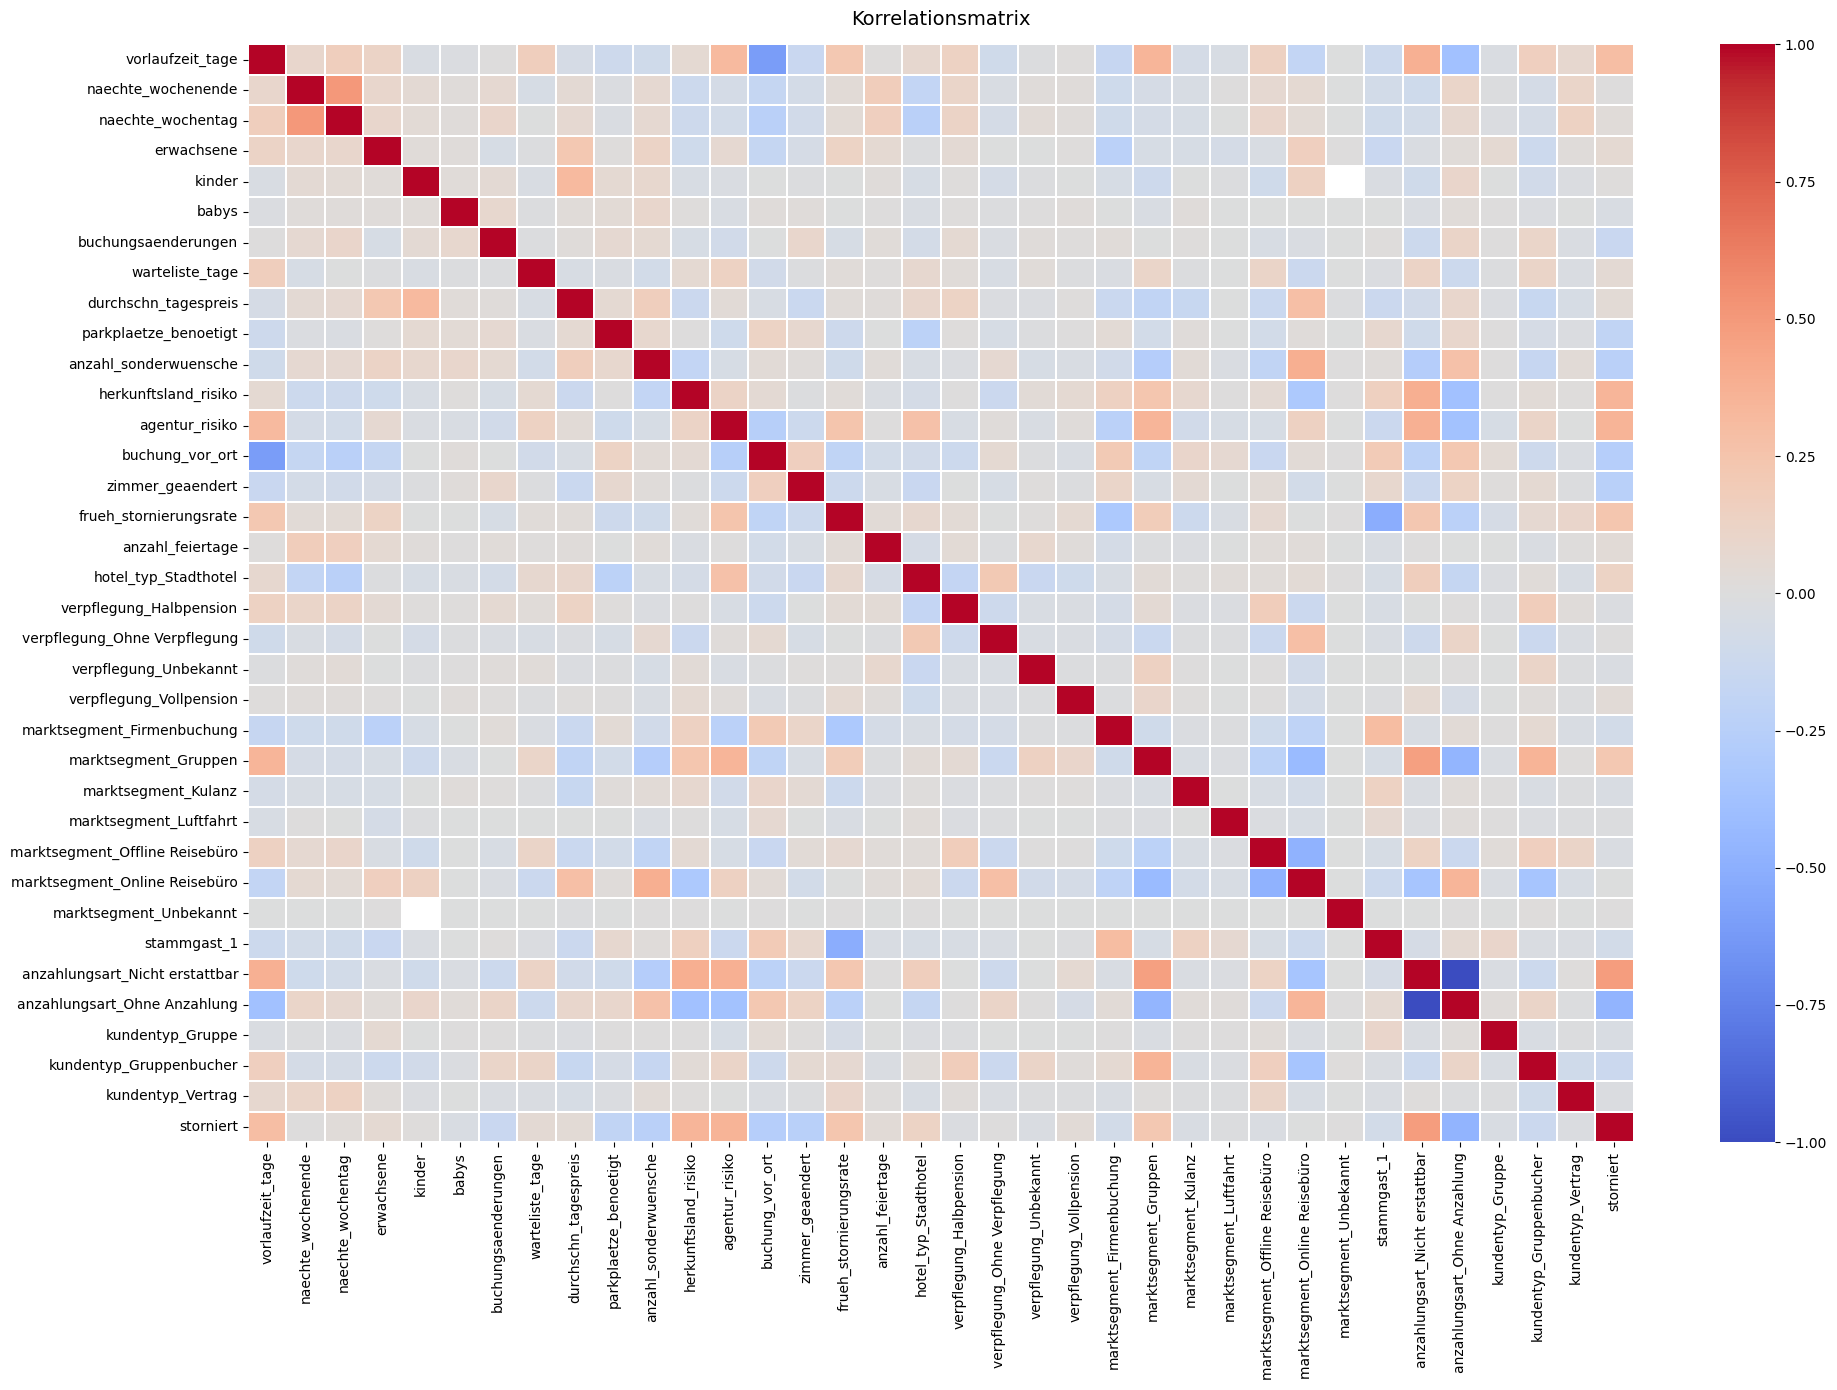

In [12]:
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder


def show_correlations(df: pd.DataFrame, target: pd.DataFrame, text: str) -> None:
    """Ausgabe der Korrelationen."""
    df_corr = df.copy()
    df_corr["storniert"] = target.copy()

    correlations = df_corr.corr()
    display(text, correlations["storniert"].sort_values(ascending=False))


show_correlations(X_train[numerical], y_train, "Korrelation der numerischen Features mit storniert:")

encoding = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first")

df_encoded = encoding.fit_transform(X=X_train[categorical])
df_encoded = pd.DataFrame(df_encoded, columns=encoding.get_feature_names_out(), index=X_train.index)

show_correlations(df_encoded, y_train, "Korrelation der kategorischen Features mit storniert:")

# Korrelationsmatrix der Features
df_heatmap = pd.concat([X_train[numerical], df_encoded], axis=1)
df_heatmap["storniert"] = y_train

_, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(
    df_heatmap.corr(),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    annot=False,
    ax=ax,
)
plt.title("Korrelationsmatrix", fontsize=14, pad=14)
plt.tight_layout()
plt.show()

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


def clip_numericals(X: np.ndarray) -> np.ndarray:
    """
    Behandlung von Ausreißern.
    Nach unten gab es keine Ausreißer, da keine negativen Werte vorhanden sind.
    """
    upper = np.percentile(X, 99, axis=0)
    return np.clip(X, 0, upper)


numerical_pipeline = Pipeline(
    [
        (
            "imputer",
            SimpleImputer(strategy="mean"),
        ),  # Ursprüngliche Überlegung: Kinder mit 0 füllen, da einzige Spalte mit NaN; bei Testdaten sind die Werte unbekannt, daher allgemeine Strategie über mean
        ("clip", FunctionTransformer(clip_numericals, validate=False)),
        ("scaler", StandardScaler()),  # Für logistische Regression
    ]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="Keine Angabe")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]
)

preprocessor = ColumnTransformer([("num", numerical_pipeline, numerical), ("cat", categorical_pipeline, categorical)])

# (4) Training der Modelle

## Mathematische Modellierung

**Mengen und Parameter:**

$I := \{1, \ldots, N\} \quad \text{(Buchungen im Datensatz)}$

$p_i \in [0,1] \quad \text{vorhergesagte Stornierungswahrscheinlichkeit für Buchung i}$

$y_i \in \{0,1\} \quad \text{tatsächlicher Stornierungsstatus}$

$c_i^{\text{FN}} := 0{,}9 \cdot \text{tagespreis}_i \cdot \text{nächte}_i \quad \text{Kosten einer nicht erkannten Stornierung}$

$c^{\text{FP}} := 250 \quad \text{Umbuchungskosten bei falsch vorhergesagter Stornierung}$

$\varepsilon := 10^{-5} \quad \text{Verhindert das beide Nebenbedingungen gleichzeitig greifen}$

**Entscheidungsvariablen:**

$t \in [0,1] \quad \text{Klassifikationsschwellwert}$

$z_i \in \{0,1\} \quad \forall i \in I \quad \text{Vorhersage } (z_i = 1  \text{ Stornierung vorhergesagt)}$

**Zielfunktion:**

$\min_{t,\, z} \quad \underbrace{\sum_{\substack{i \in I \\ y_i = 0}} c^{\text{FP}} \cdot z_i}_{\text{Falsch-Positive}} \;+\; \underbrace{\sum_{\substack{i \in I \\ y_i = 1}} c_i^{\text{FN}} \cdot (1 - z_i)}_{\text{Falsch-Negative}}$

**Nebenbedingungen**:

$p_i - t \;\geq\; -M\,(1 - z_i) \quad \forall i \in I \quad \text{wenn } z_i = 1 \rightarrow p_i \geq t$

$p_i - t \;\leq\; M \cdot z_i - \varepsilon \quad \forall i \in I  \quad \text{wenn } z_i = 0 \rightarrow p_i < t$

$t \in [0,\, 1] $

$z_i \in \{0,\, 1\} \quad \forall i \in I$

In [14]:
import gurobipy as gp
from gurobipy import GRB


def optimize_threshold_gurobi(y_true: pd.Series, y_prob: pd.Series, df_features: pd.DataFrame) -> tuple[float, float]:
    aufenthaltsdauer = df_features["naechte_wochenende"] + df_features["naechte_wochentag"]
    fn_kosten = (df_features["durchschn_tagespreis"] * aufenthaltsdauer * 0.9).values

    true_values = y_true.values
    vorhersage_wahrscheinlichkeit = y_prob  # Vorhergesagte Stornierungswahrscheinlichkeit
    anzahl_buchungen = len(true_values)

    env = gp.Env(empty=True)
    env.setParam("OutputFlag", 0)
    env.start()
    model = gp.Model("Threshold_Optimierung", env=env)

    threshold = model.addVar(vtype=GRB.CONTINUOUS, lb=0.0, ub=1.0, name="threshold")
    vorhersage = model.addVars(anzahl_buchungen, vtype=GRB.BINARY, name="z")

    M = 1.01  # Muss größer als max|p_i - t| = 1 sein
    eps = 1e-5  # verhindert Gleichheit bei p_i = t

    # Nebenbedingungen: legen fest, ob Vorhersage als storniert oder nicht storniert erfasst werden soll.
    for i in range(anzahl_buchungen):
        model.addConstr(vorhersage_wahrscheinlichkeit[i] - threshold >= -M * (1 - vorhersage[i]), name=f"lower_{i}")
        model.addConstr(vorhersage_wahrscheinlichkeit[i] - threshold <= M * vorhersage[i] - eps, name=f"upper_{i}")

    gesamtkosten = gp.LinExpr()
    for i in range(anzahl_buchungen):
        if true_values[i] == 0:
            gesamtkosten += 250.0 * vorhersage[i]
        else:
            gesamtkosten += fn_kosten[i] * (1 - vorhersage[i])

    model.setObjective(gesamtkosten, GRB.MINIMIZE)
    model.optimize()

    if model.status == GRB.OPTIMAL:
        return model.ObjVal, threshold.X
    raise ValueError("Gurobi konnte keine optimale Lösung finden.")

In [15]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import GridSearchCV


def show_metrics(y_true: pd.DataFrame, y_pred: pd.DataFrame, title: str = "") -> None:
    """Ausgabe der relevanten Metriken."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    print(
        f"{title}\n"
        f"Accuracy:             {accuracy_score(y_true, y_pred) * 100:.7f}\n"
        f"Precision:            {precision_score(y_true, y_pred) * 100:.7f}\n"
        f"Recall:               {recall_score(y_true, y_pred) * 100:.7f}\n"
        f"False positive rate:  {fp / (fp + tn) * 100:.7f}\n"
    )


def show_feature_importances(model, name: str) -> None:
    """Ausgabe der Feature Importances."""
    onehot = model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
    feature_names_cat = onehot.get_feature_names_out(categorical)

    feature_names = numerical.tolist() + feature_names_cat.tolist()

    # Wichtigkeit der Features beim splitten
    importances = model.named_steps[name].feature_importances_

    df_importances = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)

    display("Feature Importances:", df_importances)


def show_permutation_importances(model) -> None:
    """Ausgabe der Permutation Importances."""
    result = permutation_importance(model, X_train, y_train, n_repeats=10, random_state=42, scoring="accuracy")

    df_importances = pd.DataFrame({"feature": X_train.columns, "importance": result.importances_mean}).sort_values("importance", ascending=False)

    display("Permutation Importances:", df_importances)


def evaluate_model(name: str, ident: str, search: GridSearchCV, output_importances: list[bool] = [False, False]) -> dict:
    """Ausgabe Modellergebnisse und Rückgabe Dictionary mit wichtigsten Parametern."""
    best_model = search.best_estimator_

    y_pred = best_model.predict(X_train)
    show_metrics(y_train, y_pred, title=f"{name} (Trainingsdaten)")

    df = X_train.copy()
    df["fehler"] = abs(y_pred - y_train)
    display(df.groupby("hotel_typ")["fehler"].describe())

    y_pred = best_model.predict(X_valid)
    show_metrics(y_valid, y_pred, title=f"{name} (Validationsdaten)")

    display("Beste Parameter:", search.best_params_)

    if output_importances[0]:
        show_feature_importances(best_model, ident)
    if output_importances[1]:
        show_permutation_importances(best_model)

    y_prob = best_model.predict_proba(X_valid)[:, 1]  # Gurobi braucht die Wahrscheinlichkeiten wie das Modell "stoniert" als Klasse einschätzt
    costs, threshold = optimize_threshold_gurobi(y_valid, y_prob, X_valid)
    # costs, threshold = 0, 0

    tn, fp, fn, tp = confusion_matrix(y_valid, y_pred).ravel()

    return {
        name: {
            "Model": best_model,
            "Parameter": search.best_params_,
            "Accuracy": round(accuracy_score(y_valid, y_pred) * 100, 2),
            "Precision": round(precision_score(y_valid, y_pred) * 100, 2),
            "Recall": round(recall_score(y_valid, y_pred) * 100, 2),
            "False positive rate": round(fp / (fp + tn) * 100, 2),
            "Gesamtkosten": costs,
            "Schwellwert": threshold,
        }
    }


models = []

In [16]:
def model_by_hotels(name: str, search: GridSearchCV):
    X_t = X_train.copy()
    X_v = X_valid.copy()

    X_t["storniert"] = y_train
    X_v["storniert"] = y_valid

    X_t["pred"] = None
    X_v["pred"] = None
    X_v["prob"] = np.nan

    models = {}

    for hotel_type in ["Stadthotel", "Ferienhotel"]:
        # Filtern von Trainingsdaten
        train_filtered = X_t[X_t["hotel_typ"] == hotel_type].copy()

        y_train_h = train_filtered["storniert"]
        X_train_h = train_filtered.drop(columns=["storniert", "pred"])

        # Filtern von Validationsdaten
        valid_filtered = X_v[X_v["hotel_typ"] == hotel_type].copy()

        X_valid_h = valid_filtered.drop(columns=["storniert", "pred"])

        search.fit(X_train_h, y_train_h)

        model = search.best_estimator_
        models[hotel_type] = model

        # Vorhersagen mit vollständigem Datensatz zusammenführen
        y_pred = model.predict(X_train_h)
        X_t.loc[train_filtered.index, "pred"] = y_pred

        y_pred = model.predict(X_valid_h)
        X_v.loc[valid_filtered.index, "pred"] = y_pred

        y_prob = model.predict_proba(X_valid_h)[:, 1]
        X_v.loc[valid_filtered.index, "prob"] = y_prob

    show_metrics(y_train, X_t["pred"].astype(int), f"{name} (Trainingsdaten)")
    show_metrics(y_valid, X_v["pred"].astype(int), f"{name} (Validationsdaten)")

    y_pred = X_v["pred"].astype(int)
    y_prob = X_v["prob"].values

    costs, threshold = optimize_threshold_gurobi(y_valid, y_prob, X_valid)
    # costs, threshold = 0, 0

    tn, fp, fn, tp = confusion_matrix(y_valid, y_pred).ravel()

    return {
        name: {
            "Model": models,
            "Parameter": None,
            "Accuracy": round(accuracy_score(y_valid, y_pred) * 100, 2),
            "Precision": round(precision_score(y_valid, y_pred) * 100, 2),
            "Recall": round(recall_score(y_valid, y_pred) * 100, 2),
            "False positive rate": round(fp / (fp + tn) * 100, 2),
            "Gesamtkosten": costs,
            "Schwellwert": threshold,
        }
    }

In [17]:
from sklearn.tree import DecisionTreeClassifier


def model_decision_tree(param_grid: dict):
    return GridSearchCV(
        estimator=Pipeline([("preprocessor", preprocessor), ("tree", DecisionTreeClassifier(random_state=42))]),
        param_grid=param_grid,
        scoring="accuracy",
        cv=CV,
        n_jobs=N_JOBS,
        verbose=VERBOSE,
    )


# Training auf ganzen Trainingsdatensatz
parameters = {
    "tree__max_depth": [10, 12, 15],
    "tree__min_samples_split": [50, 100, 200],
    "tree__min_samples_leaf": [10, 20, 50],
    "tree__criterion": ["gini", "entropy"],
}

search = model_decision_tree(parameters)
search.fit(X_train, y_train)

models.append(evaluate_model("Entscheidungsbaum", "tree", search, [True, True]))

# Training getrennt nach Hotels
parameters = {
    "tree__max_depth": [5, 8, 10],
    "tree__min_samples_split": [20, 50, 100],
    "tree__min_samples_leaf": [20, 50, 100],
    "tree__criterion": ["gini", "entropy"],
}

search = model_decision_tree(parameters)
models.append(model_by_hotels("Entscheidungsbaum (getrennt)", search))

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Entscheidungsbaum (Trainingsdaten)
Accuracy:             86.8456288
Precision:            85.7548845
Recall:               77.2123108
False positive rate:  7.5121768



,count,mean,std,min,25%,50%,75%,max
hotel_typ,,,,,,,,
Ferienhotel,25602.0,0.112647,0.316168,0.0,0.0,0.0,0.0,1.0
Stadthotel,50578.0,0.141109,0.348137,0.0,0.0,0.0,0.0,1.0


Entscheidungsbaum (Validationsdaten)
Accuracy:             85.8290455
Precision:            83.7681612
Recall:               76.3600114
False positive rate:  8.6410512



'Beste Parameter:'

{'tree__criterion': 'entropy',
 'tree__max_depth': 15,
 'tree__min_samples_leaf': 10,
 'tree__min_samples_split': 50}

'Feature Importances:'

,feature,importance
30,anzahlungsart_Nicht erstattbar,0.331357
11,herkunftsland_risiko,0.129612
12,agentur_risiko,0.095683
0,vorlaufzeit_tage,0.092885
14,zimmer_geaendert,0.055108
10,anzahl_sonderwuensche,0.050726
9,parkplaetze_benoetigt,0.049986
33,kundentyp_Gruppenbucher,0.040861
8,durchschn_tagespreis,0.035688
15,frueh_stornierungsrate,0.033625


'Permutation Importances:'

,feature,importance
11,anzahlungsart,0.070677
17,herkunftsland_risiko,0.065068
18,agentur_risiko,0.057201
16,anzahl_sonderwuensche,0.055492
1,vorlaufzeit_tage,0.045349
13,kundentyp,0.038020
8,marktsegment,0.027145
20,zimmer_geaendert,0.021344
14,durchschn_tagespreis,0.014354
21,frueh_stornierungsrate,0.013824


GurobiError: Model too large for size-limited license; visit https://gurobi.com/unrestricted for more information

In [ ]:
from sklearn.linear_model import LogisticRegression


def model_logistic_regression(param_grid: dict) -> GridSearchCV:
    return GridSearchCV(
        estimator=Pipeline([("preprocessor", preprocessor), ("logistic", LogisticRegression(random_state=42))]),
        param_grid=param_grid,
        scoring="accuracy",
        cv=CV,
        n_jobs=N_JOBS,
        verbose=VERBOSE,
)

# Training auf ganzen Trainingsdatensatz
parameters = {
    "logistic__C": [0.01, 0.1, 1, 10],
    "logistic__penalty": ["l2"],
    "logistic__solver": ["lbfgs"],
    "logistic__max_iter": [500],
}

search = model_logistic_regression(parameters)
search.fit(X_train, y_train)

models.append(evaluate_model("Logistische Regression", "logistic", search, [False, True]))

# Training getrennt nach Hotels
parameters = {
    "logistic__C": [0.001, 0.01, 0.1, 1],
    "logistic__penalty": ["l2"],
    "logistic__solver": ["lbfgs"],
    "logistic__max_iter": [300],
}

search = model_logistic_regression(parameters)
models.append(model_by_hotels("Logistische Regression (getrennt)", search))

In [ ]:
from sklearn.ensemble import RandomForestClassifier


def model_random_forest(param_grid: dict) -> GridSearchCV:
    return GridSearchCV(
        estimator=Pipeline([("preprocessor", preprocessor), ("rf", RandomForestClassifier(random_state=42))]),
        param_grid=param_grid,
        scoring="accuracy",
        cv=CV,
        n_jobs=N_JOBS,
        verbose=VERBOSE,
    )


# Training auf ganzen Trainingsdatensatz
parameters = {
    "rf__n_estimators": [200, 300],
    "rf__max_depth": [20, None],
    "rf__min_samples_split": [10, 20],
    "rf__min_samples_leaf": [2, 4],
    "rf__max_features": ["sqrt"],
}

search = model_random_forest(parameters)
search.fit(X_train, y_train)

models.append(evaluate_model("Random Forest", "rf", search, [True, True]))

# Training getrennt nach Hotels
parameters = {
    "rf__n_estimators": [300, 500],
    "rf__max_depth": [20, None],
    "rf__min_samples_split": [5, 10, 20],
    "rf__min_samples_leaf": [1, 2, 4],
    "rf__max_features": ["sqrt"],
}

search = model_random_forest(parameters)
models.append(model_by_hotels("Random Forest (getrennt)", search))

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier


def model_gradient_boosting(param_grid: dict) -> GridSearchCV:
    return GridSearchCV(
        estimator=Pipeline([("preprocessor", preprocessor), ("gb", GradientBoostingClassifier(random_state=42))]),
        param_grid=param_grid,
        scoring="accuracy",
        cv=CV,
        n_jobs=N_JOBS,
        verbose=VERBOSE,
    )


# Training auf ganzen Trainingsdatensatz
parameters = {
    "gb__n_estimators": [100, 200],
    "gb__learning_rate": [0.05, 0.1],
    "gb__max_depth": [3, 4],
    "gb__subsample": [0.8],
}

search = model_gradient_boosting(parameters)
search.fit(X_train, y_train)

models.append(evaluate_model("Gradient Boosting", "gb", search, [True, True]))

# Training getrennt nach Hotels
parameters = {
    "gb__n_estimators": [100, 200],
    "gb__learning_rate": [0.05, 0.1, 0.2],
    "gb__max_depth": [3, 4, 5],
    "gb__subsample": [0.8, 1.0],
}

search = model_gradient_boosting(parameters)
models.append(model_by_hotels("Gradient Boosting (getrennt)", search))

In [ ]:
from sklearn.ensemble import StackingClassifier


def model_stacking(param_grid: dict, dt_depth: int, gb: list[int, int], rf: list[int, int], lg_iter: int) -> GridSearchCV:
    return GridSearchCV(
        estimator=Pipeline(
            [
                ("preprocessor", preprocessor),
                (
                    "stack",
                    StackingClassifier(
                        estimators=[
                            ("tree", DecisionTreeClassifier(max_depth=dt_depth, min_samples_split=10, random_state=42)),
                            ("gb", GradientBoostingClassifier(n_estimators=gb[0], learning_rate=0.2, max_depth=gb[1], random_state=42)),
                            ("rf", RandomForestClassifier(n_estimators=rf[0], max_depth=rf[1], random_state=42)),
                        ],
                        final_estimator=LogisticRegression(max_iter=lg_iter, random_state=42),
                        cv=CV,
                        n_jobs=N_JOBS,
                    ),
                ),
            ]
        ),
        param_grid=param_grid,
        scoring="accuracy",
        cv=CV,
        n_jobs=N_JOBS,
        verbose=VERBOSE,
    )


# Training auf ganzen Trainingsdatensatz
parameters = {"stack__final_estimator__C": [0.1, 1, 10], "stack__final_estimator__penalty": ["l2"]}

search = model_stacking(parameters, 10, [150, 3], [300, 12], 500)
search.fit(X_train, y_train)

models.append(evaluate_model("Stacking", "stack", search, [True, True]))

# Training getrennt nach Hotels
search = model_stacking(parameters, 8, [150, 3], [300, 12], 300)
models.append(model_by_hotels("Stacking (getrennt)", search))

# (5) Evaluation

Stacking verursacht die geringsten Gesamtkosten und hat die beste Accuracy.

In [ ]:
lowest_cost_model = min(models, key=lambda x: next(iter(x.values()))["Gesamtkosten"])

rows = []

for model in models:
    name, values = next(iter(model.items()))

    rows.append(
        {
            "name": name,
            "Gesamtkosten": values["Gesamtkosten"],
            "Schwellwert": values["Schwellwert"],
            "Accuracy": values["Accuracy"],
            "Precision": values["Precision"],
            "Recall": values["Recall"],
            "False positive rate": values["False positive rate"],
        }
    )

df_models = pd.DataFrame(rows)
df_models = df_models.sort_values(by="Gesamtkosten")

display("Modelle nach Gesamtkosten:", df_models.reset_index(drop=True))

# (6) Vorhersage

In [ ]:
df_models = df_models.sort_values(by="Accuracy", ascending=False)

display("Modelle nach Accuracy:", df_models.drop(columns=["Gesamtkosten", "Schwellwert"]).reset_index(drop=True))

In [ ]:
sorted_models = sorted(models, key=lambda x: next(iter(x.values()))["Accuracy"], reverse=True)
best_entry = sorted_models[0]

name, values = next(iter(best_entry.items()))
best_model = values["Model"]

df_test = features(df_test)

# Falls das beste Validationsergebnis mit nach Hotels getrennter Modellierung erzielt wurde,
# muss das hier auch beim Erstellen der Vorhersage berücksichtigt werden
if "(getrennt)" in name:
    df_test["storniert"] = None
    for hotel_type in ["Stadthotel", "Ferienhotel"]:
        X = df_train[df_train["hotel_typ"] == hotel_type].drop(columns=["storniert"])
        y = df_train[df_train["hotel_typ"] == hotel_type]["storniert"]

        model = best_model[hotel_type]
        model.fit(X, y)

        X_test = df_test[df_test["hotel_typ"] == hotel_type]
        X_test = X_test.drop(columns=["storniert"])

        # Anmerkung: Falls die Vorhersage deutlich schlechter wie erwartet sein sollte,
        # wird hier wohl beim Zusammenführen ein Fehler passiert sein
        df_test.loc[X_test.index, "storniert"] = model.predict(X_test)
else:
    X = df_train.drop(columns=["storniert"])
    y = df_train["storniert"]

    best_model.fit(X, y)

    df_test["storniert"] = best_model.predict(df_test)

df_test[["buchungs_id", "storniert"]].to_csv("data/vorhersage.csv", index=False)